In [13]:
import pandas as pd

In [14]:
import numpy as np

In [15]:
import statsmodels as stmo

In [16]:
from pathlib import Path

file = Path(
    r"C:\Users\kwang\OneDrive - HC-SC PHAC-ASPC\Desktop\FB Bot.xlsx"
)

print(file.exists())
print(file.is_file())

True
True


In [20]:
DysonDaniels = pd.read_excel(
    r"C:\Users\kwang\OneDrive - HC-SC PHAC-ASPC\Desktop\FB Bot.xlsx",
    sheet_name="DysonDaniels"
)

print(DysonDaniels.head())

        Date   Opp      Score Type              Min  FGM  FGA   FG%  3PM  3PA  \
0 2026-04-10   CLE  W 102-124  Reg   1 day, 5:30:00    6   10  60.0    0    1   
1 2026-04-08  @CLE  L 116-122  Reg   1 day, 9:03:00    5   11  45.5    1    3   
2 2026-04-06    NY  L 108-105  Reg  1 day, 13:53:00    4   11  36.4    1    3   
3 2026-04-03  @BKN  W 141-107  Reg   1 day, 5:29:00    5    8  62.5    1    2   
4 2026-04-01  @ORL  W 130-101  Reg   1 day, 7:04:00    5   11  45.5    1    2   

   ... OR  DR  Reb Ast  Stl  Blk  TO  PF  +/-  Pts  
0  ...  5   5   10  12    2    0   1   2   36   13  
1  ...  1   6    7   6    2    1   1   6   -5   12  
2  ...  6   6   12   3    2    0   1   6    1   11  
3  ...  1   3    4   6    5    0   2   0   29   11  
4  ...  6   7   13   4    1    0   3   2   19   15  

[5 rows x 24 columns]


In [21]:
DysonDaniels["Stl"].describe()

count    76.000000
mean      1.960526
std       1.226820
min       0.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       5.000000
Name: Stl, dtype: float64

<Axes: >

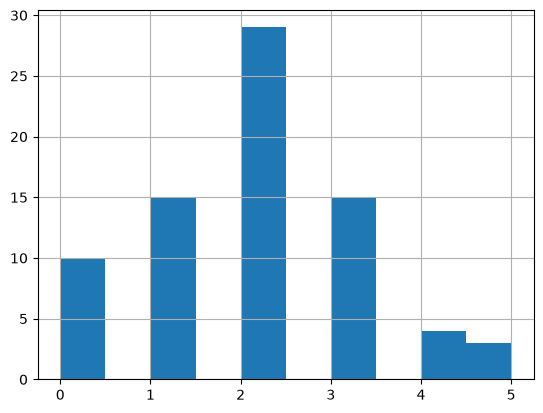

In [23]:
DysonDaniels["Stl"].hist()

In [26]:
import numpy as np

history = DysonDaniels["Stl"]

sum(
    np.random.choice(
        history,
        size=3
    )
)

np.int64(6)

In [27]:
DysonDaniels["Stl"].value_counts().sort_index()

Stl
0    10
1    15
2    29
3    15
4     4
5     3
Name: count, dtype: int64

In [29]:
import numpy as np

stl_history = DysonDaniels["Stl"]

results = []

for i in range(100000):

    total = np.random.choice(
        stl_history,
        size=3,
        replace=True
    ).sum()

    results.append(total)

print(np.mean(results))

print(
    np.percentile(
        results,
        [5,50,95]
    )
)

5.8794
[3. 6. 9.]


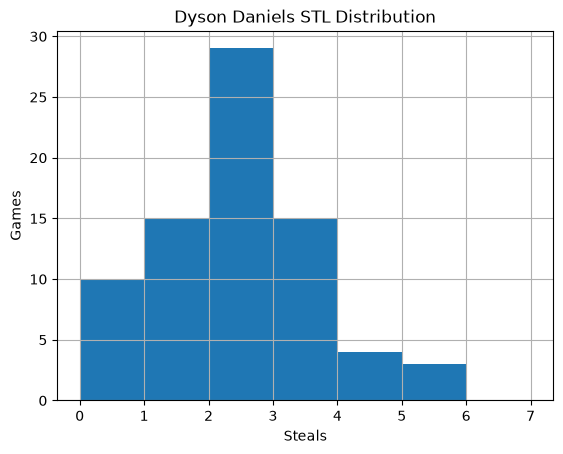

In [30]:
import matplotlib.pyplot as plt

DysonDaniels["Stl"].hist(
    bins=range(0,8)
)

plt.title("Dyson Daniels STL Distribution")
plt.xlabel("Steals")
plt.ylabel("Games")

plt.show()

In [32]:
season_mean = DysonDaniels["Stl"].mean()

recent20_mean = DysonDaniels["Stl"].tail(20).mean()

print(season_mean)
print(recent20_mean)

1.9605263157894737
2.2


In [35]:
Opponent = pd.read_excel(
    r"C:\Users\kwang\OneDrive - HC-SC PHAC-ASPC\Desktop\FB Bot.xlsx",
    sheet_name="Opponent"
)

print(Opponent.head())

        Date   Opp      Score Type             Min  FGM  FGA   FG%  3PM  3PA  \
0 2026-04-08  @LAC  W 128-110  Reg        21:00:00    1    6  16.7    1    5   
1 2026-04-07  @LAL   W 123-87  Reg        22:43:00    1    4  25.0    1    2   
2 2026-04-05   UTA  W 111-146  Reg        21:58:00    6   10  60.0    4    5   
3 2026-04-02   LAL   W 96-139  Reg        21:11:00    3    7  42.9    2    5   
4 2026-03-30   DET  W 110-114  Reg  1 day, 2:33:00    4    9  44.4    1    5   

   ... OR  DR  Reb Ast  Stl  Blk  TO  PF  +/-  Pts  
0  ...  0   2    2   1    0    1   2   1    2    3  
1  ...  2   0    2   3    3    0   0   4   27    5  
2  ...  0   5    5   1    2    0   0   0   20   16  
3  ...  1   4    5   2    1    0   0   1   28    8  
4  ...  0   0    0   1    0    0   1   2    1    9  

[5 rows x 24 columns]


In [37]:
my_total = 24 + np.random.choice(
    DysonDaniels["Stl"],
    size=3,
    replace=True).sum()


opp_total = 26 + np.random.choice(
    Opponent["Stl"],
    size=3,
    replace=True).sum()





In [43]:
wins = 0
margins = []

for i in range(10000):

    my_total = 25 + np.random.choice(
        DysonDaniels["Stl"],
        size=3,
        replace=True
    ).sum()

    opp_total = 26 + np.random.choice(
        Opponent["Stl"],
        size=3,
        replace=True
    ).sum()

    margins.append(my_total - opp_total)

    if my_total > opp_total:
        wins += 1

print("Average margin:")
print(np.mean(margins))

print("Win probability:")
print(wins / 10000)

Average margin:
-0.9606
Win probability:
0.3293


In [44]:
print(f"Win Prob = {wins/10000:.1%}")

print(f"Avg Margin = {np.mean(margins):.2f}")

print(np.percentile(
    margins,
    [5,25,50,75,95]
))

Win Prob = 32.9%
Avg Margin = -0.96
[-6. -3. -1.  1.  4.]


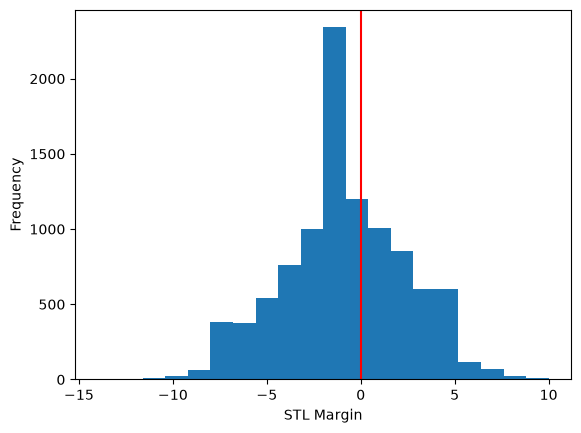

In [45]:
import matplotlib.pyplot as plt

plt.hist(margins,bins=20)

plt.axvline(
    x=0,
    color="red"
)

plt.xlabel("STL Margin")
plt.ylabel("Frequency")

plt.show()

In [49]:
import pandas as pd
import numpy as np

# ============================================================
# 1. 讀取資料
# ============================================================

file = r"C:\Users\kwang\OneDrive - HC-SC PHAC-ASPC\Desktop\FB Bot.xlsx"

MyPlayer = pd.read_excel(
    file,
    sheet_name="DysonDaniels"
)

Opponent = pd.read_excel(
    file,
    sheet_name="Opponent"
)


# ============================================================
# 2. 建立 Recency Weight
# ============================================================

def add_weights(df, decay=0.99):

    df = df.copy()

    # 日期轉成真正日期格式
    df["Date"] = pd.to_datetime(df["Date"])

    # 最新一場放最上面
    df = df.sort_values(
        "Date",
        ascending=False
    ).reset_index(drop=True)

    # 最近一場 = 1
    # 前一場 = 0.99
    # 前兩場 = 0.99^2
    # ...
    df["Weight"] = decay ** np.arange(len(df))

    return df


MyPlayer = add_weights(MyPlayer, decay=0.99)
Opponent = add_weights(Opponent, decay=0.99)


# ============================================================
# 3. 看一下 Weight 是否正確
# ============================================================

print("My Player weights:")

print(
    MyPlayer[
        ["Date", "Weight"]
    ].head(10)
)

print()

print("Oldest games:")

print(
    MyPlayer[
        ["Date", "Weight"]
    ].tail(5)
)


# ============================================================
# 4. 目前比分
# ============================================================

current_my = {
    "Pts": 120,
    "Reb": 48,
    "Ast": 35,
    "Stl": 24,
    "Blk": 8,
    "3PM": 18,
    "TO": 16
}

current_opp = {
    "Pts": 118,
    "Reb": 52,
    "Ast": 38,
    "Stl": 26,
    "Blk": 10,
    "3PM": 17,
    "TO": 18
}


# ============================================================
# 5. 雙方剩餘比賽
# ============================================================

my_games_left = 3
opp_games_left = 3


# ============================================================
# 6. 模擬 Categories
# ============================================================

categories = [
    "Pts",
    "Reb",
    "Ast",
    "Stl",
    "Blk",
    "3PM",
    "TO"
]


# ============================================================
# 7. Monte Carlo
# ============================================================

n_sim = 10000

win_counts = {
    cat: 0
    for cat in categories
}

margin_dict = {
    cat: []
    for cat in categories
}


for sim in range(n_sim):

    # --------------------------------------------------------
    # 關鍵：
    # 每次抽「整場比賽」，不是各 category 分開抽
    # --------------------------------------------------------

    my_sample = MyPlayer.sample(
        n=my_games_left,
        replace=True,
        weights="Weight"
    )

    opp_sample = Opponent.sample(
        n=opp_games_left,
        replace=True,
        weights="Weight"
    )

    # --------------------------------------------------------
    # 抽完三場之後，才把每個 category 加總
    # --------------------------------------------------------

    for cat in categories:

        my_future = my_sample[cat].sum()
        opp_future = opp_sample[cat].sum()

        my_total = (
            current_my[cat]
            + my_future
        )

        opp_total = (
            current_opp[cat]
            + opp_future
        )

        margin = (
            my_total
            - opp_total
        )

        margin_dict[cat].append(
            margin
        )

        # TO 越少越好
        if cat == "TO":

            if my_total < opp_total:
                win_counts[cat] += 1

        else:

            if my_total > opp_total:
                win_counts[cat] += 1


# ============================================================
# 8. 輸出結果
# ============================================================

print()
print("=" * 60)
print("WEIGHTED BOOTSTRAP CATEGORY WIN PROBABILITIES")
print("=" * 60)


for cat in categories:

    win_prob = (
        win_counts[cat]
        / n_sim
    )

    mean_margin = np.mean(
        margin_dict[cat]
    )

    p5, p50, p95 = np.percentile(
        margin_dict[cat],
        [5, 50, 95]
    )

    print()

    print(cat)

    print(
        f"Win Prob  : {win_prob:.1%}"
    )

    print(
        f"Avg Margin: {mean_margin:.2f}"
    )

    print(
        f"P5/P50/P95: "
        f"{p5:.1f}, "
        f"{p50:.1f}, "
        f"{p95:.1f}"
    )

My Player weights:
        Date    Weight
0 2026-12-31  1.000000
1 2026-12-29  0.990000
2 2026-12-27  0.980100
3 2026-12-26  0.970299
4 2026-12-21  0.960596
5 2026-12-19  0.950990
6 2026-12-18  0.941480
7 2026-12-14  0.932065
8 2026-12-12  0.922745
9 2026-12-06  0.913517

Oldest games:
         Date    Weight
71 2026-01-09  0.489890
72 2026-01-07  0.484991
73 2026-01-05  0.480141
74 2026-01-03  0.475340
75 2026-01-02  0.470587

WEIGHTED BOOTSTRAP CATEGORY WIN PROBABILITIES

Pts
Win Prob  : 82.7%
Avg Margin: 12.68
P5/P50/P95: -10.0, 13.0, 34.0

Reb
Win Prob  : 89.6%
Avg Margin: 7.37
P5/P50/P95: -2.0, 7.0, 16.0

Ast
Win Prob  : 86.8%
Avg Margin: 7.17
P5/P50/P95: -2.0, 7.0, 17.0

Stl
Win Prob  : 22.1%
Avg Margin: -2.03
P5/P50/P95: -7.0, -2.0, 3.0

Blk
Win Prob  : 6.7%
Avg Margin: -1.83
P5/P50/P95: -4.0, -2.0, 1.0

3PM
Win Prob  : 12.7%
Avg Margin: -2.14
P5/P50/P95: -7.0, -2.0, 1.0

TO
Win Prob  : 29.5%
Avg Margin: 0.89
P5/P50/P95: -4.0, 1.0, 5.0


In [48]:
import pandas as pd
import numpy as np

file = r"C:\Users\kwang\OneDrive - HC-SC PHAC-ASPC\Desktop\FB Bot.xlsx"

MyPlayer = pd.read_excel(
    file,
    sheet_name="DysonDaniels"
)

# 確保日期是日期格式
MyPlayer["Date"] = pd.to_datetime(DD["Date"])

# 最新比賽排第一
MyPlayer = MyPlayer.sort_values("Date", ascending=False).reset_index(drop=True)

# 建立權重
MyPlayer["Weight"] = 0.99 ** np.arange(len(MyPlayer))

# 轉成抽樣機率
MyPlayer["Probability"] = MyPlayer["Weight"] / MyPlayer["Weight"].sum()

MyPlayer[["Date", "Weight", "Probability"]].head(10)

,Date,Weight,Probability
0,2026-12-31,1.000000,0.018722
1,2026-12-29,0.990000,0.018535
2,2026-12-27,0.980100,0.018350
3,2026-12-26,0.970299,0.018166
4,2026-12-21,0.960596,0.017985
5,2026-12-19,0.950990,0.017805
6,2026-12-18,0.941480,0.017627
7,2026-12-14,0.932065,0.017451
8,2026-12-12,0.922745,0.017276
9,2026-12-06,0.913517,0.017103


In [50]:
!pip install nba_api


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from nba_api.stats.static import players

result = players.find_players_by_full_name("Dyson Daniels")



In [3]:
from nba_api.stats.endpoints import playergamelog

dyson_id = result[0]["id"]

log = playergamelog.PlayerGameLog(
    player_id=dyson_id,
    season="2025-26",
    season_type_all_star="Regular Season"
)

DD = log.get_data_frames()[0]

DD.head()

SSLError: HTTPSConnectionPool(host='stats.nba.com', port=443): Max retries exceeded with url: /stats/playergamelog?DateFrom=&DateTo=&LeagueID=00&PlayerID=1630700&Season=2025-26&SeasonType=Regular+Season (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-signed certificate in certificate chain (_ssl.c:1032)')))